# Chapitre 6 - Cours 6 : moteurs de synchronisation, local-first et CRDT

Le cours 3 a présenté la réplication multi-leader entre régions. Poussée à l'extrême,
elle décrit aussi les applications qui fonctionnent **hors ligne** et celles qui
permettent la **collaboration en temps réel** : chaque appareil, voire chaque onglet de
navigateur, devient un leader. Ce cours, propre à la 2e édition, couvre la section *Sync
Engines and Local-First Software* et la partie *Automatic conflict resolution* /
*Conflict-free replicated datatypes and operational transformation* de *Dealing with
Conflicting Writes*. Le code est dans [`ddia/crdt.py`](../../ddia/crdt.py).

**Plan.**

1. Un leader par appareil : les moteurs de synchronisation.
2. Temps réel, hors ligne d'abord, local-first.
3. Avantages et limites d'un moteur de synchronisation.
4. CRDT : compteurs et ensembles qui convergent tout seuls.
5. Texte collaboratif : transformation opérationnelle contre CRDT.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import crdt
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Un leader par appareil (section *Sync Engines and Local-First Software*)

L'agenda de votre téléphone, de votre portable et de votre tablette doit rester
consultable **et modifiable** sans connexion ; les modifications faites hors ligne sont
synchronisées avec le serveur et les autres appareils au retour du réseau. Chaque
appareil a donc une **base locale qui accepte les écritures** (un leader), et une
réplication multi-leader asynchrone, la **synchronisation**, relie les répliques ; le
retard peut atteindre des heures ou des jours. C'est la configuration multi-régions du
cours 3 poussée à l'extrême : chaque appareil est une « région », reliée aux autres par
un réseau extrêmement peu fiable.

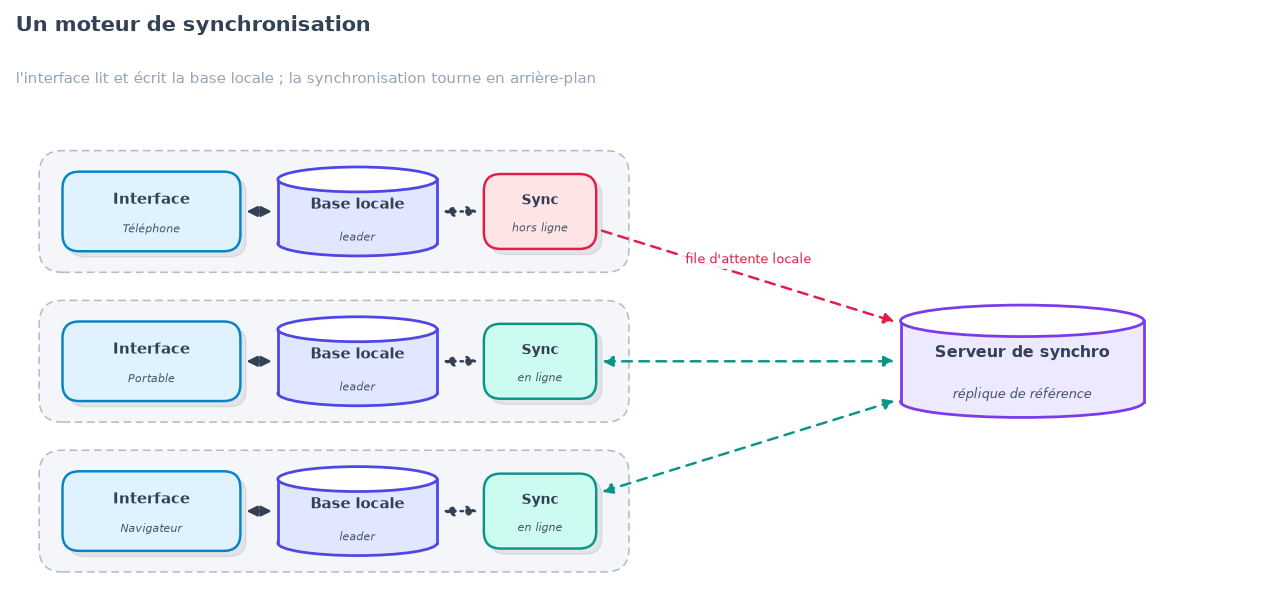

In [2]:
d = Diagram(13.5, 5.2, title="Un moteur de synchronisation",
            subtitle="l'interface lit et écrit la base locale ; la synchronisation tourne en arrière-plan")
for i, (nom, y, etat) in enumerate([("Téléphone", 4.0, "hors ligne"), ("Portable", 2.4, "en ligne"), ("Navigateur", 0.8, "en ligne")]):
    d.group(0.3, y - 0.65, 6.6, y + 0.65, None, color=SLATE)
    d.box(f"ui{i}", 1.5, y, "Interface", sub=nom, color=SKY, w=1.9, h=0.85, fontsize=9.5)
    d.box(f"db{i}", 3.7, y, "Base locale", sub="leader", color=INDIGO, kind="db", w=1.7, h=0.95, fontsize=9.5)
    d.box(f"se{i}", 5.65, y, "Sync", sub=etat, color=ROSE if etat == "hors ligne" else TEAL, w=1.2, h=0.8, fontsize=9)
    d.arrow(f"ui{i}", f"db{i}", both=True)
    d.arrow(f"db{i}", f"se{i}", both=True, style="dotted")
d.box("srv", 10.8, 2.4, "Serveur de synchro", sub="réplique de référence", color=VIOLET, kind="db", w=2.6, h=1.2)
d.arrow("se0", "srv", "file d'attente locale", style="dashed", color=ROSE)
d.arrow("se1", "srv", both=True, style="dashed", color=TEAL)
d.arrow("se2", "srv", both=True, style="dashed", color=TEAL)
d.show()

> **À retenir.** Une application qui doit fonctionner hors ligne est un système
> multi-leader : chaque appareil accepte des écritures et se synchronise plus tard,
> avec un retard potentiellement très long.